# Лабораторная работа 1. Моделирование БСВ.

## Условие задачи

**Вариант 10.**

Используя метод Макларена-Марсальи, построить датчик БСВ (1 датчик должен быть мультипликативно конгруэнтный, второй — на выбор). Исследовать точность построенной БСВ.

1. Осуществить моделирование $n = 1000$ реализаций БСВ с помощью мультипликативного конгруэнтного метода (МКМ) с параметрами $a_0 = \beta = 16807$, $M = 2^{31}$.

2. Осуществить моделирование $n = 1000$ реализаций БСВ с помощью метода Макларена-Марсальи (один датчик должен быть мультипликативно конгруэнтный (п. 1), второй — на выбор). $K = 64$ — объём вспомогательной таблицы.

3. Проверить точность моделирования обоих датчиков (п. 1 и п. 2) с помощью критерия согласия Колмогорова и $\chi^2$-критерия Пирсона с уровнем значимости $\varepsilon = 0.05$.

# Теория

## Мультипликативный конгруэнтный метод

Псевдослучайная последовательность $\alpha_1, \alpha_2, \ldots, \alpha_n$ строится по следующим рекуррентным формулам:

$$
\alpha_t = \alpha_t^* / M, \qquad \alpha_t^* = \{\beta \, \alpha_{t-1}^*\} \bmod M, \qquad t = 1, 2, \ldots
$$

где $\beta, M, \alpha_0$ — параметры датчика: $\beta$ — множитель ($\beta < M$), $M$ — модуль, $\alpha_i \in \{1, \ldots, M-1\}$ — стартовое значение (нечётное число).

В данной работе для **первого (МКМ) датчика** брались значения:

$$
M = 2^{31} = 2147483648, \qquad \alpha_0 = \beta = 16807.
$$

## Метод Макларена-Марсальи

Пусть $\{b_i\}$, $\{c_i\}$ — псевдослучайные последовательности, порождённые независимо работающими датчиками; $\{\alpha_i\}$ — результирующая псевдослучайная последовательность реализаций БСВ; $V = \{V(0), V(1), \ldots, V(K-1)\}$ — вспомогательная таблица $K$ чисел. Процесс вычисления $\{\alpha_i\}$ включает следующие этапы:

- первоначальное заполнение таблицы:

$$
V(i) = b_i, \qquad i = \overline{0, K-1};
$$

- случайный выбор из таблицы:

$$
\alpha_i = V(s), \qquad s = [c_i \cdot K];
$$

- обновление табличных значений:

$$
V(s) = b_{t+K}, \qquad t = 0, 1, 2, \ldots
$$

В данной работе в качестве $\{b_i\}$ бралась последовательность, полученная мультипликативным конгруэнтным методом с параметрами $\beta = 16807$, $M = 2^{31}$. В качестве $\{c_i\}$ бралась последовательность, полученная аналогичным способом с тем же $M$ и $\beta' = 65539$. Объём вспомогательной таблицы $K = 64$.

## $\chi^2$-критерий согласия Пирсона

Область возможных значений случайной величины разбивается на интервалы $[x_{k-1}, x_k]$, $k = 1, K$. Рассматривается следующая статистика:

$$
\chi^2 = \sum_{k=1}^{K} \frac{(\nu_k - n \, p_k)^2}{n \, p_k},
$$

$n$ — объём выборки,

$\nu_k$ — количество элементов выборки, попавших в $k$-й интервал,

$p_k$ — вероятность попадания случайной величины в $k$-й интервал.

Проверяется условие $\chi^2 < \Delta$, где $\Delta = G^{-1}(1 - \varepsilon)$, $G$ — функция распределения $\chi^2$, $\varepsilon$ — уровень значимости (обычно $\varepsilon = 0.05$).

В данной работе отрезок $[0; 1]$ разбивался на 10 интервалов.

## Критерий согласия Колмогорова

Рассматривается статистика:

$$
D_n = \sup_{x \in \mathbb{R}} \left| \hat{F}_\xi(x) - F_0(x) \right| \in [0, 1],
$$

где

$$
\hat{F}_\xi(x) = \frac{1}{n} \sum_{i=1}^{n} I_{(-\infty, x]}(x_i), \qquad x \in \mathbb{R},
$$

$F_0(x)$ — функция распределения равномерного закона на $[0, 1]$.

Проверяется условие $\sqrt{n} \, D_n < \Delta$, где $\Delta = K^{-1}(1 - \varepsilon)$, $K$ — функция распределения распределения Колмогорова, $\varepsilon$ — уровень значимости.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

M = 2**31
BETA = 16807
A0 = 16807
N = 1000
K = 64
EPS = 0.05

BETA2 = 65539
A0_2  = 65539

print(f"M = {M}, β = {BETA}, a0 = {A0}, n = {N}, K = {K}, ε = {EPS}")

M = 2147483648, β = 16807, a0 = 16807, n = 1000, K = 64, ε = 0.05


In [11]:
def generate_mkm(a0, beta, m, n):
    seq = np.zeros(n)
    x = a0
    for i in range(n):
        x = (beta * x) % m
        seq[i] = x / m
    return seq

mkm_seq = generate_mkm(A0, BETA, M, N)
print("Первые 10 чисел МКМ:")
print(np.round(mkm_seq[:10], 6))
print(f"min = {mkm_seq.min():.6f}, max = {mkm_seq.max():.6f}")
print(f"mean = {mkm_seq.mean():.6f}, std = {mkm_seq.std():.6f}")
print(f"(теор. mean = 0.5, std = 1/√12 ≈ {1/np.sqrt(12):.6f})")

Первые 10 чисел МКМ:
[0.131538 0.755604 0.441348 0.734865 0.874772 0.285829 0.933821 0.72843
 0.731379 0.280764]
min = 0.001368, max = 0.992595
mean = 0.493272, std = 0.288056
(теор. mean = 0.5, std = 1/√12 ≈ 0.288675)


In [12]:
def generate_mm(a0_b, beta_b, a0_c, beta_c, m, n, k):
    V = np.zeros(k)
    x_b = a0_b
    for i in range(k):
        x_b = (beta_b * x_b) % m
        V[i] = x_b / m

    seq = np.zeros(n)
    x_c = a0_c
    for i in range(n):
        x_c = (beta_c * x_c) % m
        c_val = x_c / m
        s = int(c_val * k)
        if s >= k:
            s = k - 1
        seq[i] = V[s]
        x_b = (beta_b * x_b) % m
        V[s] = x_b / m
    return seq

mm_seq = generate_mm(A0, BETA, A0_2, BETA2, M, N, K)
print("Первые 10 чисел ММ:")
print(np.round(mm_seq[:10], 6))
print(f"min = {mm_seq.min():.6f}, max = {mm_seq.max():.6f}")
print(f"mean = {mm_seq.mean():.6f}, std = {mm_seq.std():.6f}")

Первые 10 чисел ММ:
[0.131538 0.533589 0.038312 0.905507 0.441348 0.280764 0.865551 0.757283
 0.85137  0.657475]
min = 0.001368, max = 0.992595
mean = 0.494572, std = 0.290214


In [4]:
def kolmogorov_test(seq, alpha=0.05):
    n = len(seq)
    s = np.sort(seq)
    d_plus  = np.max(np.arange(1, n+1) / n - s)
    d_minus = np.max(s - np.arange(0, n) / n)
    D_n = max(d_plus, d_minus)
    sqrt_n_D = math.sqrt(n) * D_n

    if abs(alpha - 0.05) < 1e-9:
        crit = 1.358
    elif abs(alpha - 0.01) < 1e-9:
        crit = 1.63
    else:
        crit = 1.358

    verdict = "H0 принимается" if sqrt_n_D < crit else "H0 ОТВЕРГАЕТСЯ"
    return D_n, sqrt_n_D, crit, verdict

print("Критерий Колмогорова")
for name, seq in [("МКМ", mkm_seq), ("ММ ", mm_seq)]:
    D, sD, crit, verdict = kolmogorov_test(seq, EPS)
    print(f"[{name}]  D_n = {D:.4f},  √n·D_n = {sD:.4f}  (крит. Δ = {crit})")
    print(f"          → {verdict}")

Критерий Колмогорова
[МКМ]  D_n = 0.0257,  √n·D_n = 0.8135  (крит. Δ = 1.358)
          → H0 принимается
[ММ ]  D_n = 0.0257,  √n·D_n = 0.8135  (крит. Δ = 1.358)
          → H0 принимается


In [5]:
def chi2_test(seq, num_bins=10, alpha=0.05):
    n = len(seq)
    delta = 1 / num_bins

    counts = np.zeros(num_bins, dtype=int)
    for x in seq:
        k = int(x * num_bins)
        if k >= num_bins:
            k = num_bins - 1
        counts[k] += 1

    p_k = delta
    expected = n * p_k

    chi2 = np.sum((counts - expected) ** 2 / expected)
    df = num_bins - 1

    chi2_table_05 = {1: 3.841, 2: 5.991, 3: 7.815, 4: 9.488,
                     5: 11.070, 6: 12.592, 7: 14.067, 8: 15.507,
                     9: 16.919, 10: 18.307}
    crit = chi2_table_05.get(df, 16.919)

    verdict = "H0 принимается" if chi2 < crit else "H0 ОТВЕРГАЕТСЯ"
    return chi2, df, crit, verdict, counts, expected

print("Критерий χ² Пирсона")
for name, seq in [("МКМ", mkm_seq), ("ММ ", mm_seq)]:
    chi2, df, crit, verdict, counts, expected = chi2_test(seq, 10, EPS)
    print(f"[{name}]  χ² = {chi2:.4f}, df = {df}, крит. Δ = {crit:.4f}")
    print(f"          ν_k (наблюд.)  = {counts.tolist()}")
    print(f"          n·p_k (ожид.)  = {expected:.1f}")
    print(f"          → {verdict}")

Критерий χ² Пирсона
[МКМ]  χ² = 7.3000, df = 9, крит. Δ = 16.9190
          ν_k (наблюд.)  = [103, 103, 110, 109, 79, 102, 97, 96, 106, 95]
          n·p_k (ожид.)  = 100.0
          → H0 принимается
[ММ ]  χ² = 6.8200, df = 9, крит. Δ = 16.9190
          ν_k (наблюд.)  = [103, 107, 109, 106, 79, 98, 97, 96, 106, 99]
          n·p_k (ожид.)  = 100.0
          → H0 принимается


In [6]:
rows = []
for name, seq in [("МКМ (β=16807)", mkm_seq), (f"ММ (K={K})", mm_seq)]:
    D, sD, critK, vK = kolmogorov_test(seq, EPS)
    chi2, df, critX, vX, _, _ = chi2_test(seq, 10, EPS)
    rows.append([name, f"{sD:.4f}", f"{critK}", vK,
                 f"{chi2:.4f}", f"{critX:.4f}", vX])

print(f"{'Датчик':<20}   {'√n·D_n':>8}   {'Δ_K':>6}   {'Колмогоров':<18}  "
      f"{'χ²':>8}   {'Δ_χ²':>8}    {'Пирсон':<18}")
print("-" * 100)
for r in rows:
    print(f"{r[0]:<20}   {r[1]:>8}   {r[2]:>6}   {r[3]:<18}   {r[4]:>8}   {r[5]:>8}   {r[6]:<18}")

Датчик                   √n·D_n      Δ_K   Колмогоров                χ²       Δ_χ²    Пирсон            
----------------------------------------------------------------------------------------------------
МКМ (β=16807)            0.8135    1.358   H0 принимается         7.3000    16.9190   H0 принимается    
ММ (K=64)                0.8135    1.358   H0 принимается         6.8200    16.9190   H0 принимается    


In [7]:
K_bins = 10
delta  = 1 / K_bins
edges  = np.arange(0, 1 + delta, delta)

def histogram_density(seq, edges, delta):
    n = len(seq)
    K_bins_local = len(edges) - 1
    m = np.zeros(K_bins_local, dtype=int)
    for x in seq:
        k = int(x / delta)
        if k >= K_bins_local:
            k = K_bins_local - 1
        m[k] += 1
    h = (m / n) / delta
    centers = (edges[:-1] + edges[1:]) / 2
    return m, h, centers

m_mkm, h_mkm, centers_mkm = histogram_density(mkm_seq, edges, delta)
m_mm,  h_mm,  centers_mm  = histogram_density(mm_seq,  edges, delta)

print("МКМ — частоты m_k:    ", m_mkm.tolist())
print("МКМ — плотности h_k:  ", np.round(h_mkm, 4).tolist())
print("ММ  — частоты m_k:    ", m_mm.tolist())
print("ММ  — плотности h_k:  ", np.round(h_mm, 4).tolist())

МКМ — частоты m_k:     [103, 103, 110, 109, 79, 102, 97, 96, 106, 95]
МКМ — плотности h_k:   [1.03, 1.03, 1.1, 1.09, 0.79, 1.02, 0.97, 0.96, 1.06, 0.95]
ММ  — частоты m_k:     [103, 107, 109, 106, 79, 98, 97, 96, 106, 99]
ММ  — плотности h_k:   [1.03, 1.07, 1.09, 1.06, 0.79, 0.98, 0.97, 0.96, 1.06, 0.99]


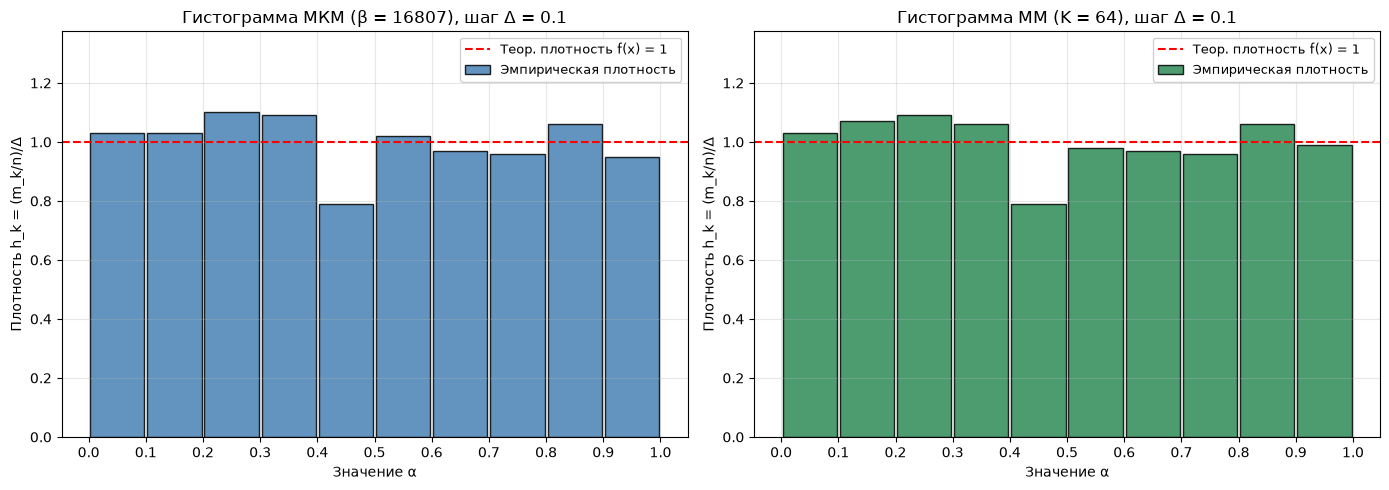

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].bar(centers_mkm, h_mkm, width=delta*0.95, color='steelblue',
          edgecolor='black', alpha=0.85, label='Эмпирическая плотность')
ax[0].axhline(1, color='red', ls='--', label='Теор. плотность f(x) = 1')
ax[0].set_title(f'Гистограмма МКМ (β = {BETA}), шаг Δ = {delta}')
ax[0].set_xlabel('Значение α')
ax[0].set_ylabel('Плотность h_k = (m_k/n)/Δ')
ax[0].set_xticks(np.arange(0, 1.01, 0.1))
ax[0].set_ylim(0, max(h_mkm.max(), h_mm.max()) * 1.25)
ax[0].legend(loc='upper right', fontsize=9, framealpha=0.9)
ax[0].grid(alpha=0.3)

ax[1].bar(centers_mm, h_mm, width=delta*0.95, color='seagreen',
          edgecolor='black', alpha=0.85, label='Эмпирическая плотность')
ax[1].axhline(1, color='red', ls='--', label='Теор. плотность f(x) = 1')
ax[1].set_title(f'Гистограмма ММ (K = {K}), шаг Δ = {delta}')
ax[1].set_xlabel('Значение α')
ax[1].set_ylabel('Плотность h_k = (m_k/n)/Δ')
ax[1].set_xticks(np.arange(0, 1.01, 0.1))
ax[1].set_ylim(0, max(h_mkm.max(), h_mm.max()) * 1.25)
ax[1].legend(loc='upper right', fontsize=9, framealpha=0.9)
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('histograms.png', dpi=120, bbox_inches='tight')
plt.show()

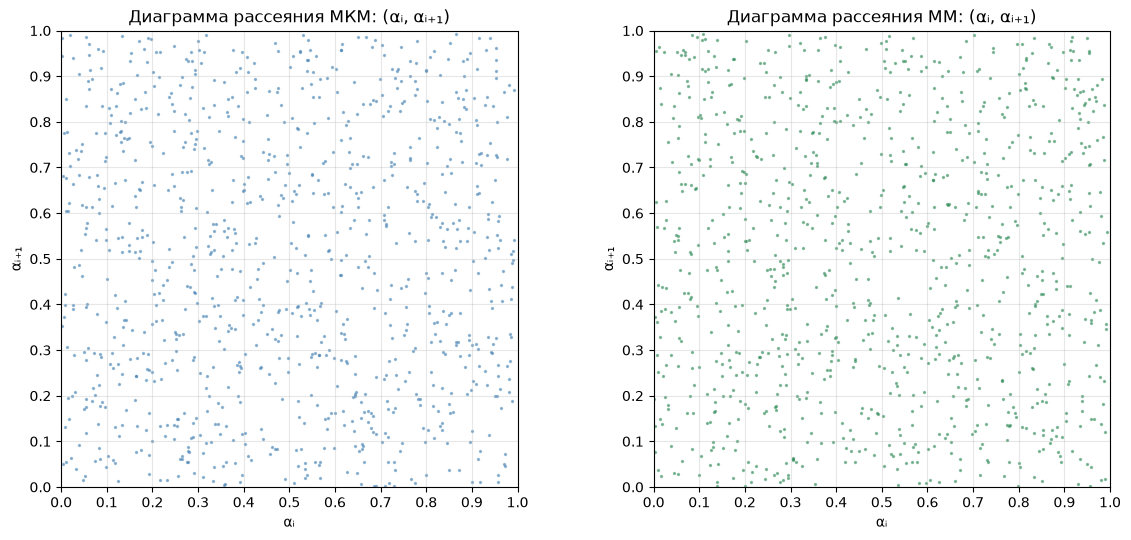

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5.5))

ax[0].scatter(mkm_seq[:-1], mkm_seq[1:], s=2, alpha=0.5, color='steelblue')
ax[0].set_title('Диаграмма рассеяния МКМ: (αᵢ, αᵢ₊₁)')
ax[0].set_xlabel('αᵢ'); ax[0].set_ylabel('αᵢ₊₁')
ax[0].set_xlim(0, 1); ax[0].set_ylim(0, 1)
ax[0].set_xticks(np.arange(0, 1.01, 0.1))
ax[0].set_yticks(np.arange(0, 1.01, 0.1))
ax[0].set_aspect('equal'); ax[0].grid(alpha=0.3)

ax[1].scatter(mm_seq[:-1], mm_seq[1:], s=2, alpha=0.5, color='seagreen')
ax[1].set_title('Диаграмма рассеяния ММ: (αᵢ, αᵢ₊₁)')
ax[1].set_xlabel('αᵢ'); ax[1].set_ylabel('αᵢ₊₁')
ax[1].set_xlim(0, 1); ax[1].set_ylim(0, 1)
ax[1].set_xticks(np.arange(0, 1.01, 0.1))
ax[1].set_yticks(np.arange(0, 1.01, 0.1))
ax[1].set_aspect('equal'); ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('scatter.png', dpi=120, bbox_inches='tight')
plt.show()

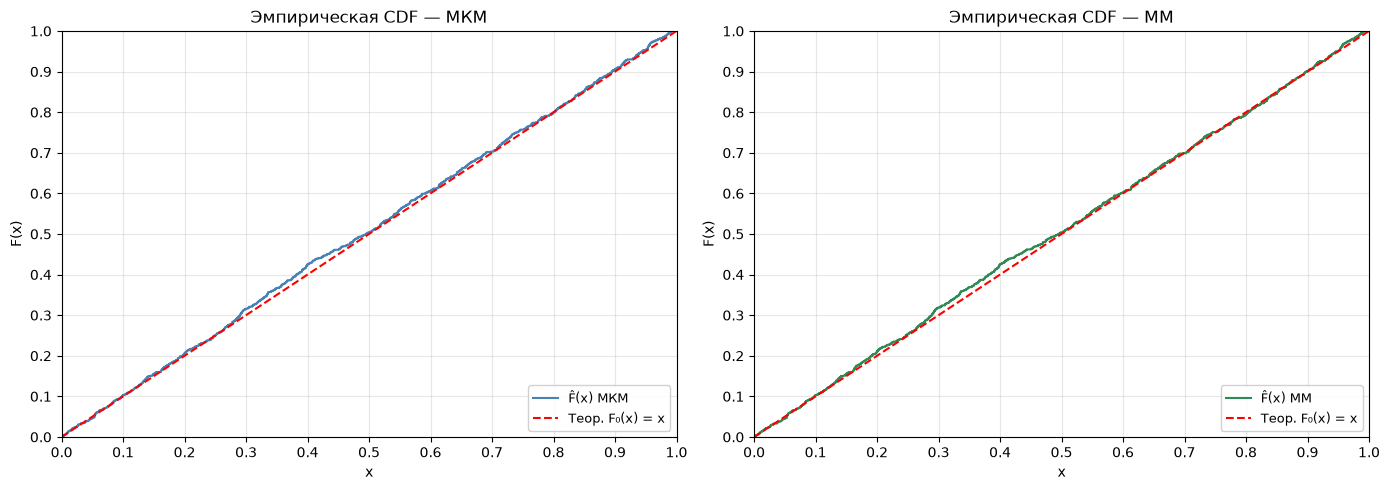

In [10]:
def plot_ecdf(seq, ax, label, color):
    n = len(seq)
    s = np.sort(seq)
    y = np.arange(1, n+1) / n
    ax.step(s, y, where='post', label=label, color=color, lw=1.5)
    ax.plot([0, 1], [0, 1], 'r--', label='Теор. F₀(x) = x')

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

plot_ecdf(mkm_seq, ax[0], 'F̂(x) МКМ', 'steelblue')
ax[0].set_title('Эмпирическая CDF — МКМ')
ax[0].set_xlabel('x'); ax[0].set_ylabel('F(x)')
ax[0].set_xlim(0, 1); ax[0].set_ylim(0, 1)
ax[0].set_xticks(np.arange(0, 1.01, 0.1))
ax[0].set_yticks(np.arange(0, 1.01, 0.1))
ax[0].legend(loc='lower right', fontsize=9, framealpha=0.9)
ax[0].grid(alpha=0.3)

plot_ecdf(mm_seq, ax[1], 'F̂(x) ММ', 'seagreen')
ax[1].set_title('Эмпирическая CDF — ММ')
ax[1].set_xlabel('x'); ax[1].set_ylabel('F(x)')
ax[1].set_xlim(0, 1); ax[1].set_ylim(0, 1)
ax[1].set_xticks(np.arange(0, 1.01, 0.1))
ax[1].set_yticks(np.arange(0, 1.01, 0.1))
ax[1].legend(loc='lower right', fontsize=9, framealpha=0.9)
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('ecdf.png', dpi=120, bbox_inches='tight')
plt.show()